In [5]:
import pandas as pd
import numpy as numpy

df = pd.read_csv("feature_selected.csv")

In [6]:
df.shape

(57303, 24)

In [11]:
# Select numerical columns
num_cols = df.select_dtypes(include=["int64", "float64"]).columns.tolist()

print("Numerical columns:")
print(num_cols)

# Summary statistics
display(df[num_cols].describe().T)

Numerical columns:
['latitude', 'longitude', 'total_owners_holding', 'scheme_depth', 'scheme_diameter', 'nearest_scheme_distance', 'construction_cost', 'horse_power_of_lifting_device', 'culturable_command_area']


,count,mean,std,min,25%,50%,75%,max
latitude,57303.0,26.314407,0.422958,24.269978,26.129345,26.288032,26.437511,2.797252e+01
longitude,57303.0,91.459174,1.447504,89.702887,90.186019,91.030726,92.381378,9.588946e+01
total_owners_holding,57303.0,1.557596,45.359578,0.000000,0.000000,1.000000,2.000000,9.000000e+03
scheme_depth,57303.0,27.468942,17.318626,0.030000,18.000000,24.000000,35.000000,8.000000e+02
scheme_diameter,57303.0,84.851908,394.257999,0.010000,12.000000,80.000000,100.000000,3.500000e+04
nearest_scheme_distance,57303.0,205.604155,180.272319,0.010000,100.000000,125.000000,300.000000,5.001000e+03
construction_cost,57303.0,157764.649250,675397.136980,0.000000,10000.000000,15000.000000,35000.000000,5.000000e+07
horse_power_of_lifting_device,57303.0,3.920200,13.571941,0.000000,2.000000,3.000000,5.000000,1.800000e+03
culturable_command_area,57303.0,3.098555,7.365185,0.000000,1.000000,2.000000,4.000000,7.500000e+02


In [12]:
df.shape

(57303, 24)

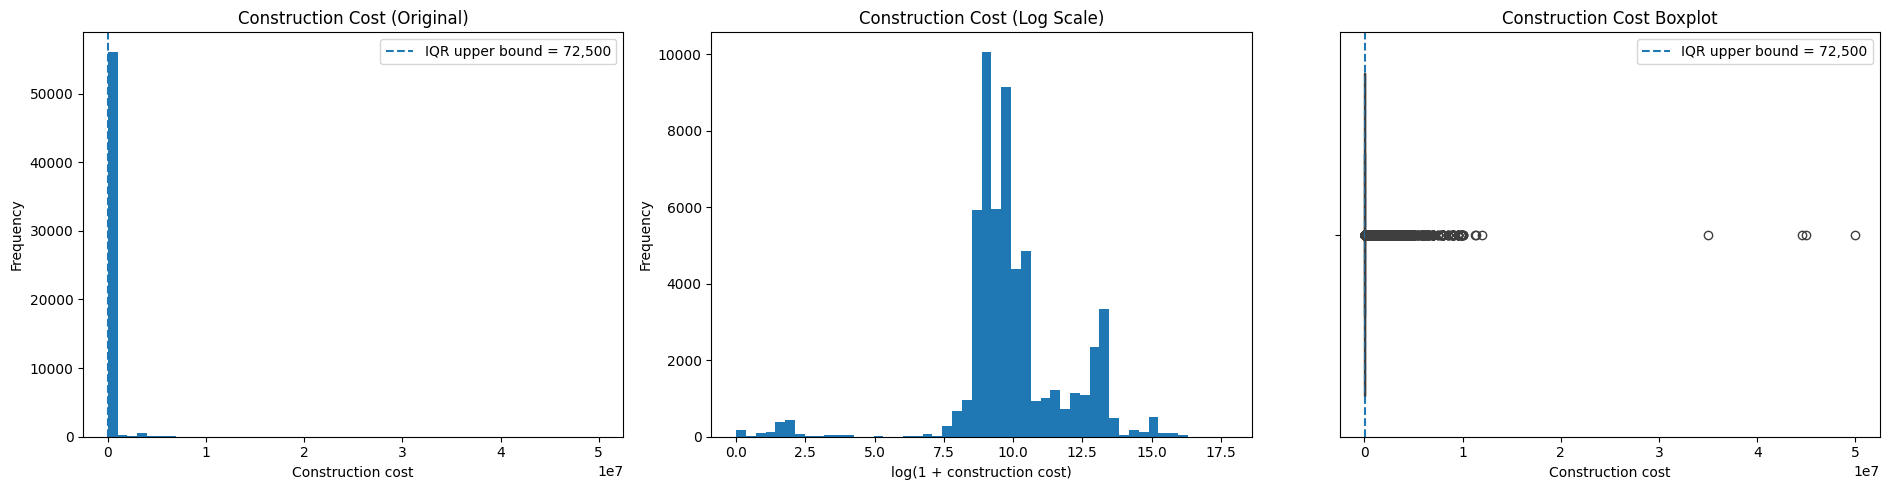

In [14]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

col = "construction_cost"
cost = df[col].dropna()

Q1 = cost.quantile(0.25)
Q3 = cost.quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# 1. Original distribution
axes[0].hist(cost, bins=50)
axes[0].axvline(
    upper_bound, linestyle="--",
    label=f"IQR upper bound = {upper_bound:,.0f}"
)
axes[0].set_title("Construction Cost (Original)")
axes[0].set_xlabel("Construction cost")
axes[0].set_ylabel("Frequency")
axes[0].legend()

# 2. Log-transformed distribution
axes[1].hist(np.log1p(cost.clip(lower=0)), bins=50)
axes[1].set_title("Construction Cost (Log Scale)")
axes[1].set_xlabel("log(1 + construction cost)")
axes[1].set_ylabel("Frequency")

# 3. Boxplot
sns.boxplot(x=cost, ax=axes[2])
axes[2].axvline(
    upper_bound, linestyle="--",
    label=f"IQR upper bound = {upper_bound:,.0f}"
)
axes[2].set_title("Construction Cost Boxplot")
axes[2].set_xlabel("Construction cost")
axes[2].legend()

plt.tight_layout()
plt.show()